# Walkthrough: one dequantized output projection

This notebook takes one pair (English to Arabic), shows the duplicated subgraph in its merged decoder, applies
the change made by `scripts/convert.py`, checks that the tokens are identical, and measures the memory.
It uses the same helpers as the scripts; the original files are downloaded once (pinned sha256).

In [1]:
import sys
sys.path.insert(0, "../scripts")

import onnx
from common import DEC, ENC, Tok, greedy, sha256, source, session, v1_dir, v2_decoder
from convert import hoist

PAIR = "en-ar"
entry = source(PAIR)
folder = v1_dir(PAIR)          # original encoder, decoder and tokenizer files
original = folder / "onnx" / DEC
print(PAIR, entry["onnx_export"], entry["onnx_revision"][:12])

en-ar Xenova/opus-mt-en-ar 034a684356c1


## 1. The duplicated subgraph

The merged decoder is a single `If` node. Each branch builds the output projection from the same 8-bit
initializer with a `Transpose` and a `DequantizeLinear`.

In [2]:
m = onnx.load(str(original))
iff = next(n for n in m.graph.node if n.op_type == "If")
print("If node:", iff.name, "| condition:", iff.input[0])
for a in iff.attribute:
    g = a.g
    for n in g.node:
        if ((n.op_type == "Transpose" and "shared.weight" in n.input[0])
                or (n.op_type == "DequantizeLinear" and "weight_transposed" in n.input[0])):
            print(f"  {g.name:10} {n.op_type:17} {n.name:48} -> {n.output[0]}")
w = next(t for t in m.graph.initializer if t.name == "model.shared.weight_merged_0_quantized")
print("weight:", w.name, list(w.dims), onnx.TensorProto.DataType.Name(w.data_type))

If node: optimum::if | condition: use_cache_branch
  no_past    Transpose         Transpose_1370                                   -> model.shared.weight_transposed_quantized
  no_past    DequantizeLinear  model.shared.weight_transposed_DequantizeLinear  -> model.shared.weight_transposed
  with_past  Transpose         Transpose_1138                                   -> model.shared.weight_transposed_quantized
  with_past  DequantizeLinear  model.shared.weight_transposed_DequantizeLinear  -> model.shared.weight_transposed
weight: model.shared.weight_merged_0_quantized [62802, 512] UINT8


## 2. The change

`hoist` moves the two nodes in front of the `If` and removes them from both branches. The result is
byte-identical to the published rebuilt decoder.

In [3]:
import tempfile
from pathlib import Path

tmp = Path(tempfile.mkdtemp())
rebuilt = tmp / DEC
hoist(original, rebuilt)
print("bytes:", original.stat().st_size, "->", rebuilt.stat().st_size)
print("same sha256 as the published file:", sha256(rebuilt) == entry["v2_decoder"]["sha256"])

r = onnx.load(str(rebuilt))
print([(n.op_type, n.name) for n in r.graph.node])

bytes: 59078120 -> 59077788
same sha256 as the published file: True
[('DynamicQuantizeLinear', 'encoder_hidden_states_QuantizeLinear'), ('Transpose', 'Transpose_1370'), ('DequantizeLinear', 'model.shared.weight_transposed_DequantizeLinear'), ('If', 'optimum::if')]


## 3. Identical tokens

Greedy decoding with the original and the rebuilt decoder, under both session settings.

In [4]:
tok = Tok(folder, entry["lang_token"])
lines = ["The lighthouse stands on the coast.", "Press E to interact",
         "Are you sure you want to quit? Unsaved progress will be lost."]
rows = [tok.encode(s) for s in lines]
for qdq_off in (False, True):
    enc = session(folder / "onnx" / ENC, qdq_off)
    old = greedy(enc, session(original, qdq_off), rows, entry["pad"])
    new = greedy(enc, session(rebuilt, qdq_off), rows, entry["pad"])
    print("disable_quant_qdq =", int(qdq_off), "| identical token ids:", old == new)
for s, ids in zip(lines, new):
    print(f"  {s}  ->  {tok.decode(ids)}")

disable_quant_qdq = 0 | identical token ids: True


disable_quant_qdq = 1 | identical token ids: True
  The lighthouse stands on the coast.  ->  المنارة تقف على الساحل
  Press E to interact  ->  اضغط E للتفاعل
  Are you sure you want to quit? Unsaved progress will be lost.  ->  هل أنت متأكد أنك تريد أن تستقيل؟ التقدم الغير منقذ سيضيع


## 4. Memory

Each configuration loads the encoder and decoder in a fresh process (`scripts/measure.py`) and reports the
resident memory the two sessions add.

In [5]:
from measure import spawn

result = {}
for config in ("v1-default", "v2-default", "v1-qdq_off", "v2-qdq_off"):
    result[config] = spawn(PAIR, config, False)["load_mib"]
    print(f"{config:11} {result[config]:7.1f} MiB")

v1-default    281.9 MiB


v2-default    220.3 MiB


v1-qdq_off    527.4 MiB


v2-qdq_off    282.0 MiB


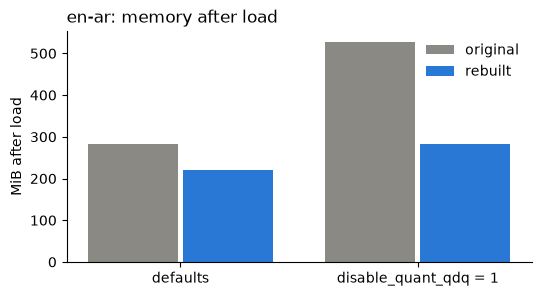

In [6]:
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "metadata": {"Software": None}}
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3))
labels = ["defaults", "disable_quant_qdq = 1"]
x = range(len(labels))
ax.bar([i - 0.2 for i in x], [result["v1-default"], result["v1-qdq_off"]], 0.38, color="#8a8984", label="original")
ax.bar([i + 0.2 for i in x], [result["v2-default"], result["v2-qdq_off"]], 0.38, color="#2a78d6", label="rebuilt")
ax.set_xticks(list(x), labels)
ax.set_ylabel("MiB after load")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title(f"{PAIR}: memory after load", loc="left")
plt.show()

In [7]:
import shutil
shutil.rmtree(tmp)